BBC News Text Classification
Goal: Classify BBC News articles into 5 categories (business, entertainment, politics, sport, tech).

Notebook outline

Data Loading
Train / Validation / Test Split
Text Preprocessing
Feature Extraction (BoW & TF-IDF)

1. Data Loading
1.1 Extract the Dataset
Unzip the BBC dataset that was manually uploaded to Colab (no internet download needed).

In [1]:
from pathlib import Path
import zipfile

# The zip is inside bbc-datasets-main/raw (one level above text_code)
zip_path = Path.cwd().parent / "raw" / "bbc-fulltext.zip"
extract_path = Path.cwd().parent / "bbc_data"

print("Zip exists:", zip_path.exists(), "->", zip_path)

# Extract directly (no need to download from the internet)
extract_path.mkdir(exist_ok=True)
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted to:", extract_path)
print(sorted(p.name for p in extract_path.iterdir()))

Zip exists: True -> C:\Users\Mostafa Ashraf\Desktop\Uni\level3\ML\project\bbc-datasets-main\raw\bbc-fulltext.zip


Extracted to: C:\Users\Mostafa Ashraf\Desktop\Uni\level3\ML\project\bbc-datasets-main\bbc_data
['bbc']


1.2 Build the DataFrame
Locate the folder that contains the five category sub-folders, then read every .txt article into a DataFrame with two columns: text and label.

In [2]:
import pandas as pd

categories = {"business", "entertainment", "politics", "sport", "tech"}

# Find the folder that contains the five category folders
data_folder = None

for folder in extract_path.rglob("*"):
    if folder.is_dir():
        child_folders = {item.name.lower() for item in folder.iterdir() if item.is_dir()}
        if categories.issubset(child_folders):
            data_folder = folder
            break

if data_folder is None:
    raise FileNotFoundError("Could not find a folder containing the five category folders.")

rows = []

for category in sorted(categories):
    category_folder = data_folder / category

    for file_path in category_folder.glob("*.txt"):
        # errors="ignore" is a safe choice here: official sources like BBC News rarely contain corrupted characters
        text = file_path.read_text(encoding="utf-8", errors="ignore")
        rows.append({
            "text": text,
            "label": category
        })

df = pd.DataFrame(rows)

print("Number of articles:", len(df))
print("Number of categories:", df["label"].nunique())
print("\nNumber of articles per category:")
print(df["label"].value_counts().sort_index())

Number of articles: 2225
Number of categories: 5

Number of articles per category:
label
business         510
entertainment    386
politics         417
sport            511
tech             401
Name: count, dtype: int64


2. Train / Validation / Test Split
2.1 Split the Data (70% / 15% / 15%)
First split off 70% for training, then divide the remaining 30% equally into validation and test sets.
stratify is used so each split keeps the same class proportions, which keeps model training and evaluation fair.

In [3]:
from sklearn.model_selection import train_test_split

# Texts and labels
X = df["text"]
y = df["label"]

# Step 1: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y   # keep the same class proportions in every split
)

# Step 2: split the 30% equally -> 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Number of training texts:", len(X_train))
print("Number of validation texts:", len(X_val))
print("Number of test texts:", len(X_test))

Number of training texts: 1557
Number of validation texts: 334
Number of test texts: 334


2.2 Verify Class Distribution
Check that the class proportions are almost identical across the train, validation, and test sets.

In [4]:
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}")
    print(labels.value_counts(normalize=True).sort_index().round(3))


Train
label
business         0.229
entertainment    0.173
politics         0.188
sport            0.229
tech             0.180
Name: proportion, dtype: float64

Validation
label
business         0.228
entertainment    0.174
politics         0.189
sport            0.231
tech             0.180
Name: proportion, dtype: float64

Test
label
business         0.231
entertainment    0.174
politics         0.186
sport            0.231
tech             0.180
Name: proportion, dtype: float64


3. Text Preprocessing
3.1 Download NLTK Stopwords

In [5]:
import nltk
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to C:\Users\Mostafa
[nltk_data]     Ashraf\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

3.2 Define the Cleaning Function
Steps: decode HTML entities and remove tags, lowercase, keep English letters only (this removes numbers and punctuation), then remove stopwords.

Note: Removing numbers may affect results. This can be revisited later based on model accuracy.

In [6]:
import re
import html
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer

stop_words = set(stopwords.words("english"))
tokenizer = RegexpTokenizer(r"[A-Za-z]+")

def clean_text(text):
    # Decode HTML entities and remove HTML tags (if any)
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)

    # Normalize letter case
    text = text.lower()

    # Keep English words only; this removes numbers and punctuation
    # (numbers might affect results, so this can be revisited based on accuracy)
    words = tokenizer.tokenize(text)

    # Remove stopwords
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

3.3 Apply Cleaning to All Splits

In [7]:
X_train_clean = X_train.apply(clean_text)
X_val_clean = X_val.apply(clean_text)
X_test_clean = X_test.apply(clean_text)

4. Feature Extraction
4.1 Bag-of-Words (BoW) & TF-IDF
BoW: counts the frequency of each word.
TF-IDF: weights words by how important they are across the corpus.
Both vectorizers are fit on the training set only, then used to transform the validation set, to avoid data leakage. The vocabulary is limited to the top 5,000 features.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# BoW: count the frequency of each word
bow_vectorizer = CountVectorizer(max_features=5000)
X_train_bow = bow_vectorizer.fit_transform(X_train_clean)

# TF-IDF: assign weights based on word importance
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_clean)

# Transform validation data using the vocabularies learned from training
X_val_bow = bow_vectorizer.transform(X_val_clean)
X_val_tfidf = tfidf_vectorizer.transform(X_val_clean)

# Display results
print("BoW Vocabulary Size:", len(bow_vectorizer.vocabulary_))
print("TF-IDF Vocabulary Size:", len(tfidf_vectorizer.vocabulary_))

print("Train BoW Shape:", X_train_bow.shape)
print("Train TF-IDF Shape:", X_train_tfidf.shape)

print("Validation BoW Shape:", X_val_bow.shape)
print("Validation TF-IDF Shape:", X_val_tfidf.shape)

BoW Vocabulary Size: 5000
TF-IDF Vocabulary Size: 5000
Train BoW Shape: (1557, 5000)
Train TF-IDF Shape: (1557, 5000)
Validation BoW Shape: (334, 5000)
Validation TF-IDF Shape: (334, 5000)


# 5. Feature Selection: Choosing the Vocabulary Size

We try different values of `max_features` (1000, 3000, 5000) for BoW and TF-IDF.
To keep it quick and fair, each vocabulary size is tested with a simple Logistic Regression model.

To avoid data leakage: every vectorizer is fit on the **training data only**, and the results are compared on the **validation set**.

In [9]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# the vocabulary sizes we want to try
feature_sizes = [1000, 3000, 5000]

# a simple model used only to compare vocabulary sizes
test_model = LogisticRegression(max_iter=5000, random_state=42)

# this list will hold one row per (representation, size)
feature_results = []

for representation in ["BoW", "TF-IDF"]:
    for size in feature_sizes:
        # create the vectorizer for the representation we are testing
        if representation == "BoW":
            vectorizer = CountVectorizer(max_features=size)
        else:
            vectorizer = TfidfVectorizer(max_features=size)

        # fit on the TRAINING data only (no leakage)
        X_train_features = vectorizer.fit_transform(X_train_clean)
        X_val_features = vectorizer.transform(X_val_clean)

        # train the model and check the scores on validation
        test_model.fit(X_train_features, y_train)
        val_predictions = test_model.predict(X_val_features)
        val_accuracy = accuracy_score(y_val, val_predictions)
        val_f1 = f1_score(y_val, val_predictions, average="macro")

        feature_results.append({
            "Representation": representation,
            "max_features": size,
            "Val Accuracy": round(val_accuracy, 4),
            "Val Macro-F1": round(val_f1, 4)
        })

# show all results as a table
feature_results_df = pd.DataFrame(feature_results)
print(feature_results_df)

# pick the best size for each representation (highest macro-F1)
bow_rows = feature_results_df[feature_results_df["Representation"] == "BoW"]
tfidf_rows = feature_results_df[feature_results_df["Representation"] == "TF-IDF"]

best_bow_size = int(bow_rows.loc[bow_rows["Val Macro-F1"].idxmax(), "max_features"])
best_tfidf_size = int(tfidf_rows.loc[tfidf_rows["Val Macro-F1"].idxmax(), "max_features"])

print()
print("Best BoW max_features:   ", best_bow_size)
print("Best TF-IDF max_features:", best_tfidf_size)

  Representation  max_features  Val Accuracy  Val Macro-F1
0            BoW          1000         0.976        0.9753
1            BoW          3000         0.979        0.9787
2            BoW          5000         0.979        0.9783
3         TF-IDF          1000         0.976        0.9758
4         TF-IDF          3000         0.982        0.9814
5         TF-IDF          5000         0.982        0.9814

Best BoW max_features:    3000
Best TF-IDF max_features: 3000


# 6. Model Training: 4 Pipelines

We build 4 pipelines (Representation x Model):
1. CountVectorizer + LogisticRegression
2. TfidfVectorizer + LogisticRegression
3. CountVectorizer + LinearSVC
4. TfidfVectorizer + LinearSVC

Each pipeline starts with the best vocabulary size found above.
The vectorizer is a step inside the pipeline, so it is always fit on training data only.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# pipeline 1: BoW + Logistic Regression
pipeline_bow_lr = Pipeline([
    ("vectorizer", CountVectorizer(max_features=best_bow_size)),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])

# pipeline 2: TF-IDF + Logistic Regression
pipeline_tfidf_lr = Pipeline([
    ("vectorizer", TfidfVectorizer(max_features=best_tfidf_size)),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])

# pipeline 3: BoW + Linear SVM
pipeline_bow_svm = Pipeline([
    ("vectorizer", CountVectorizer(max_features=best_bow_size)),
    ("model", LinearSVC(max_iter=10000, random_state=42, dual="auto"))
])

# pipeline 4: TF-IDF + Linear SVM
pipeline_tfidf_svm = Pipeline([
    ("vectorizer", TfidfVectorizer(max_features=best_tfidf_size)),
    ("model", LinearSVC(max_iter=10000, random_state=42, dual="auto"))
])

# keep them together in one dict, with a short name for each
pipelines_dict = {
    "BoW + LogisticRegression": pipeline_bow_lr,
    "TF-IDF + LogisticRegression": pipeline_tfidf_lr,
    "BoW + LinearSVC": pipeline_bow_svm,
    "TF-IDF + LinearSVC": pipeline_tfidf_svm
}

# quick baseline: fit each pipeline on train, check accuracy on validation
for pipeline_name, current_pipeline in pipelines_dict.items():
    current_pipeline.fit(X_train_clean, y_train)
    baseline_accuracy = current_pipeline.score(X_val_clean, y_val)
    print(pipeline_name, "-> Validation Accuracy:", round(baseline_accuracy, 4))

BoW + LogisticRegression -> Validation Accuracy: 0.979


TF-IDF + LogisticRegression -> Validation Accuracy: 0.982


BoW + LinearSVC -> Validation Accuracy: 0.9731


TF-IDF + LinearSVC -> Validation Accuracy: 0.976


# 7. Hyperparameter Tuning (GridSearchCV + PredefinedSplit)

Rules we follow to avoid data leakage:
- The vectorizer and the model live in the **same pipeline**, so during cross-validation the vectorizer is re-fit only on the training fold of each split.
- We combine Train + Validation into one dataset, and use `PredefinedSplit` to keep our original split: training rows get `test_fold = -1`, validation rows get `test_fold = 0`.
- The test set is never touched here.

Grid:
- `vectorizer__max_features`: 1000, 3000, 5000
- `model__C`: 0.01, 0.1, 1, 10, 100

Scoring: macro-F1 (used for refit) and accuracy (also recorded).

In [11]:
import numpy as np
from sklearn.model_selection import GridSearchCV, PredefinedSplit

# combine train + validation into one dataset
X_combined = pd.concat([X_train_clean, X_val_clean], ignore_index=True)
y_combined = pd.concat([y_train, y_val], ignore_index=True)

# build the test_fold list: -1 = training row, 0 = validation row
test_fold = []
for i in range(len(X_train_clean)):
    test_fold.append(-1)
for i in range(len(X_val_clean)):
    test_fold.append(0)
test_fold = np.array(test_fold)

# this split keeps our original Train/Validation separation
predefined_split = PredefinedSplit(test_fold)

# sanity check: 1 CV round with 1557 train rows / 334 validation rows
for train_indices, val_indices in predefined_split.split():
    print("CV training rows:", len(train_indices))
    print("CV validation rows:", len(val_indices))

CV training rows: 1557
CV validation rows: 334


In [12]:
# the same grid for every pipeline: vocabulary size + model strength (C)
param_grid = {
    "vectorizer__max_features": [1000, 3000, 5000],
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# we record macro-F1 (the refit metric) and accuracy for every combination
scoring_metrics = {
    "f1_macro": "f1_macro",
    "accuracy": "accuracy"
}

# dict to store the fitted grid searches, one per pipeline
grid_searches_dict = {}

for pipeline_name, current_pipeline in pipelines_dict.items():
    grid_search = GridSearchCV(
        estimator=current_pipeline,
        param_grid=param_grid,
        cv=predefined_split,
        scoring=scoring_metrics,
        refit="f1_macro",   # refit the best model (by macro-F1) at the end, like refit=True
        n_jobs=-1
    )

    # fit on the combined Train+Validation data (PredefinedSplit does the separation)
    grid_search.fit(X_combined, y_combined)

    grid_searches_dict[pipeline_name] = grid_search

    best_accuracy = grid_search.cv_results_["mean_test_accuracy"][grid_search.best_index_]
    print(pipeline_name)
    print("  Best params:", grid_search.best_params_)
    print("  Best CV Macro-F1:", round(grid_search.best_score_, 4))
    print("  CV Accuracy at best params:", round(best_accuracy, 4))
    print()

BoW + LogisticRegression
  Best params: {'model__C': 1, 'vectorizer__max_features': 3000}
  Best CV Macro-F1: 0.9787
  CV Accuracy at best params: 0.979



TF-IDF + LogisticRegression
  Best params: {'model__C': 1, 'vectorizer__max_features': 3000}
  Best CV Macro-F1: 0.9814
  CV Accuracy at best params: 0.982



BoW + LinearSVC
  Best params: {'model__C': 0.01, 'vectorizer__max_features': 3000}
  Best CV Macro-F1: 0.9783
  CV Accuracy at best params: 0.979



TF-IDF + LinearSVC
  Best params: {'model__C': 0.1, 'vectorizer__max_features': 5000}
  Best CV Macro-F1: 0.9814
  CV Accuracy at best params: 0.982



# 8. Model Comparison on Validation

We compare the 4 tuned pipelines (each with its best params) on the **validation set**.
The winner is the pipeline with the highest Macro-F1.

In [13]:
# evaluate every tuned pipeline on the validation set
comparison_results = []

for pipeline_name, grid_search in grid_searches_dict.items():
    best_pipeline = grid_search.best_estimator_

    # predictions on the validation set
    val_predictions = best_pipeline.predict(X_val_clean)
    val_accuracy = accuracy_score(y_val, val_predictions)
    val_f1 = f1_score(y_val, val_predictions, average="macro")

    comparison_results.append({
        "Pipeline": pipeline_name,
        "Val Accuracy": round(val_accuracy, 4),
        "Val Macro-F1": round(val_f1, 4),
        "Best max_features": grid_search.best_params_["vectorizer__max_features"],
        "Best C": grid_search.best_params_["model__C"]
    })

comparison_df = pd.DataFrame(comparison_results)
print(comparison_df)

# find the winner (highest Macro-F1 on validation)
winner_index = comparison_df["Val Macro-F1"].idxmax()
winner_name = comparison_df.loc[winner_index, "Pipeline"]
winner_pipeline = grid_searches_dict[winner_name].best_estimator_

print()
print("WINNER:", winner_name)
print("Winner params:", grid_searches_dict[winner_name].best_params_)

                      Pipeline  Val Accuracy  Val Macro-F1  Best max_features  \
0     BoW + LogisticRegression         1.000        1.0000               3000   
1  TF-IDF + LogisticRegression         0.991        0.9905               3000   
2              BoW + LinearSVC         1.000        1.0000               3000   
3           TF-IDF + LinearSVC         0.991        0.9905               5000   

   Best C  
0    1.00  
1    1.00  
2    0.01  
3    0.10  

WINNER: BoW + LogisticRegression
Winner params: {'model__C': 1, 'vectorizer__max_features': 3000}


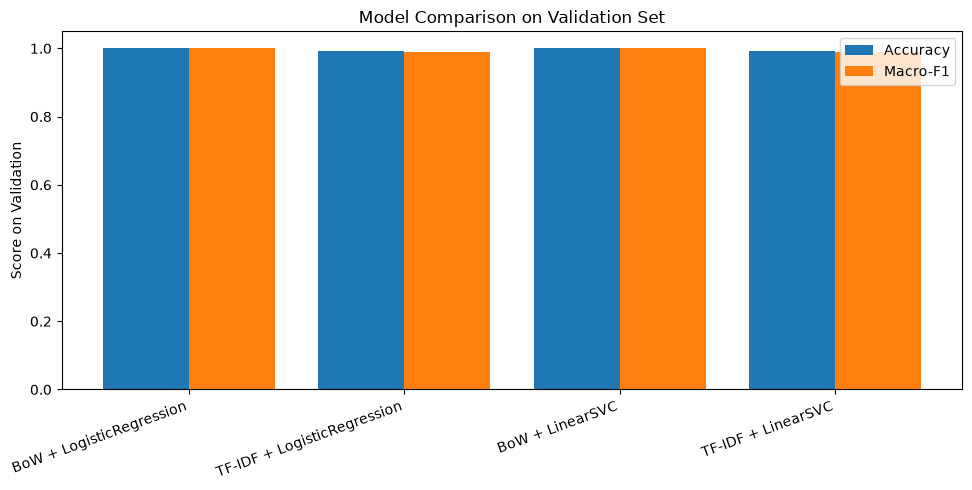

In [14]:
import matplotlib.pyplot as plt

# positions for the 4 pipelines on the x axis
x_positions = range(len(comparison_df))
pipeline_names = list(comparison_df["Pipeline"])

# shift the bars so the two bars of each pipeline sit side by side
accuracy_positions = []
f1_positions = []
for x in x_positions:
    accuracy_positions.append(x - 0.2)
    f1_positions.append(x + 0.2)

plt.figure(figsize=(10, 5))
plt.bar(accuracy_positions, comparison_df["Val Accuracy"], width=0.4, label="Accuracy")
plt.bar(f1_positions, comparison_df["Val Macro-F1"], width=0.4, label="Macro-F1")

plt.xticks(x_positions, pipeline_names, rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.ylabel("Score on Validation")
plt.title("Model Comparison on Validation Set")
plt.legend()
plt.tight_layout()
plt.show()

# 9. Final Testing (only once)

The winning pipeline is evaluated on the **test set exactly once**.
The pipeline transforms the test text with the vectorizer that was learned from the training data (no leakage, because the vectorizer is a pipeline step).

Test Accuracy: 0.979
Test Macro-F1: 0.9791


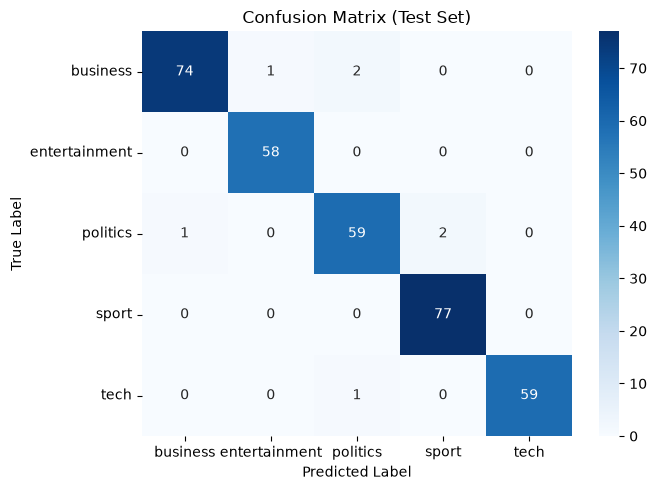

               precision    recall  f1-score   support

     business       0.99      0.96      0.97        77
entertainment       0.98      1.00      0.99        58
     politics       0.95      0.95      0.95        62
        sport       0.97      1.00      0.99        77
         tech       1.00      0.98      0.99        60

     accuracy                           0.98       334
    macro avg       0.98      0.98      0.98       334
 weighted avg       0.98      0.98      0.98       334



In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# use the test set ONLY here, one single time
test_predictions = winner_pipeline.predict(X_test_clean)
test_accuracy = accuracy_score(y_test, test_predictions)
test_f1 = f1_score(y_test, test_predictions, average="macro")

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro-F1:", round(test_f1, 4))

# class names in a fixed order
class_names = sorted(y_test.unique())

# confusion matrix as a heatmap
conf_matrix = confusion_matrix(y_test, test_predictions, labels=class_names)

plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

# precision / recall / f1 per class
print(classification_report(y_test, test_predictions))

## 10.1 Extra Experiment: Effect of Stopword Removal

Our cleaning function removes English stopwords. Here we rebuild the same winning pipeline on texts cleaned **without** stopword removal, and compare both versions on the validation set.

In [16]:
from sklearn.base import clone

# same cleaning as before, but WITHOUT removing stopwords
def clean_text_no_stopwords(text):
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    words = tokenizer.tokenize(text)
    return " ".join(words)

# clean the texts again, keeping the stopwords this time
X_train_with_stopwords = X_train.apply(clean_text_no_stopwords)
X_val_with_stopwords = X_val.apply(clean_text_no_stopwords)

# clone = a fresh copy of the winner with the same best parameters

# version WITH stopword removal (our current winner, trained on X_train_clean)
pipeline_with_stopwords = clone(winner_pipeline)
pipeline_with_stopwords.fit(X_train_clean, y_train)
predictions_with = pipeline_with_stopwords.predict(X_val_clean)
f1_with = f1_score(y_val, predictions_with, average="macro")
accuracy_with = accuracy_score(y_val, predictions_with)

# version WITHOUT stopword removal
pipeline_without_stopwords = clone(winner_pipeline)
pipeline_without_stopwords.fit(X_train_with_stopwords, y_train)
predictions_without = pipeline_without_stopwords.predict(X_val_with_stopwords)
f1_without = f1_score(y_val, predictions_without, average="macro")
accuracy_without = accuracy_score(y_val, predictions_without)

# compare the two versions
stopword_comparison = pd.DataFrame({
    "Version": ["With stopword removal", "Without stopword removal"],
    "Val Accuracy": [round(accuracy_with, 4), round(accuracy_without, 4)],
    "Val Macro-F1": [round(f1_with, 4), round(f1_without, 4)]
})
print(stopword_comparison)

                    Version  Val Accuracy  Val Macro-F1
0     With stopword removal        0.9790        0.9787
1  Without stopword removal        0.9731        0.9725


## 10.2 Confusion Matrix Analysis

We look at which classes get mixed up the most, and show a few misclassified articles from the test set.

In [17]:
# list every off-diagonal cell: true class vs predicted class
print("Confused class pairs (true -> predicted):")
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and conf_matrix[i, j] > 0:
            print(" ", class_names[i], "->", class_names[j], ":", conf_matrix[i, j], "articles")

Confused class pairs (true -> predicted):
  business -> entertainment : 1 articles
  business -> politics : 2 articles
  politics -> business : 1 articles
  politics -> sport : 2 articles
  tech -> politics : 1 articles


In [18]:
# show a few misclassified articles (true label vs predicted label)
print("Examples of misclassified articles:")
shown_count = 0
for i in range(len(y_test)):
    true_label = y_test.iloc[i]
    predicted_label = test_predictions[i]
    if true_label != predicted_label and shown_count < 5:
        print()
        print("Article number:", i)
        print("True label:", true_label, "| Predicted:", predicted_label)
        print("Text (first 250 characters):")
        print(X_test_clean.iloc[i][:250], "...")
        shown_count = shown_count + 1

Examples of misclassified articles:

Article number: 102
True label: politics | Predicted: sport
Text (first 250 characters):
blunkett hints election call ex home secretary david blunkett given fresh clues general election announced monday told bbc radio five live constituency getting ready presume announcement shortly weekend clarified meant would sheffield seat weekend ex ...

Article number: 113
True label: business | Predicted: politics
Text (first 250 characters):
uk young top euro earnings league british children enjoy highest average annual income europe double spanish italian youngsters report suggests children uk ages annual income said market analyst datamonitor use pester power get parents stump nearly t ...

Article number: 120
True label: tech | Predicted: politics
Text (first 250 characters):
iran jails blogger years iranian weblogger jailed years charges spying aiding foreign counter revolutionaries arash sigarchi arrested last month using blog criticise arrest online jo

## 10.3 Top Words per Class

Linear models learn one weight per word for each class. The words with the largest positive weight for a class are the words that push the model towards predicting that class.

In [19]:
# get the vectorizer and the model from the winning pipeline
winner_vectorizer = winner_pipeline.named_steps["vectorizer"]
winner_model = winner_pipeline.named_steps["model"]

# all words in the vocabulary (same order as the coefficient columns)
feature_names = winner_vectorizer.get_feature_names_out()

# the classes in the same order as the coefficient rows
model_classes = winner_model.classes_

print("Top 10 words per class:")
for class_index in range(len(model_classes)):
    current_class = model_classes[class_index]
    current_weights = winner_model.coef_[class_index]

    # sort the word indices from the biggest weight to the smallest
    sorted_indices = current_weights.argsort()[::-1]

    top_words = []
    for word_index in sorted_indices[:10]:
        top_words.append(feature_names[word_index])

    print()
    print(current_class, ":", ", ".join(top_words))

Top 10 words per class:

business : bn, bank, firm, shares, company, economic, market, economy, business, however

entertainment : show, film, singer, music, tv, band, star, album, films, sold

politics : party, blair, secretary, labour, mr, government, mps, election, lord, commons

sport : match, win, players, club, season, team, cup, champion, coach, olympic

tech : software, online, game, computer, digital, technology, users, people, sony, million


# 11. Final Report

## Why BoW or TF-IDF?
In the vocabulary-size experiment (section 5), TF-IDF was slightly ahead of BoW (macro-F1 0.9814 vs 0.9787 at 3000 features). But after full tuning (section 8), the two **BoW** pipelines reached a perfect validation score (1.000) while the TF-IDF pipelines scored 0.991. The winner is **BoW + LogisticRegression**, so for this dataset plain word counts were enough — the classes are already well separated by clear topic words, so the extra TF-IDF weighting did not add anything.

## Effect of stopword removal (section 10.1)
- With stopword removal: accuracy 0.9790, macro-F1 0.9787
- Without stopword removal: accuracy 0.9731, macro-F1 0.9725

Removing stopwords helped by about **+0.6 points** of macro-F1. Words like "the" and "and" carry no topic information, so dropping them leaves a smaller, more informative vocabulary.

## Logistic Regression vs Linear SVM
The two models were almost identical (BoW versions both scored 1.000 on validation, TF-IDF versions both 0.991). Logistic Regression won by arriving first with the same macro-F1, and it also gives probabilities. Interestingly, LinearSVC preferred much smaller C values (0.01–0.1, i.e. stronger regularization), while LogisticRegression preferred C = 1.

## Hyperparameters tried and final winning values
- `max_features`: 1000, 3000, 5000 -> best = **3000**
- `C`: 0.01, 0.1, 1, 10, 100 -> best = **1** for the winner (BoW + LogisticRegression)
- 15 combinations per pipeline (3 vocab sizes x 5 C values) were tested with GridSearchCV + PredefinedSplit, scored by macro-F1.

## Confusion analysis (section 10.2)
Only 7 of 334 test articles were misclassified. The most confused pairs were **business <-> politics** (3 articles) — both talk about jobs, spending, taxes and the economy — and **politics -> sport** (2 articles, election campaign stories that read like event news). The tech -> politics error was a story about a jailed blogger, which is full of political vocabulary ("government", "spying", "arrest") even though it was filed under tech.

## Limitations and possible improvements
- The test set is small (334 articles), so the final score has some randomness; k-fold cross-validation on train+validation would give a more stable estimate.
- We only used single words (unigrams); adding bigrams (`ngram_range=(1, 2)`) would capture phrases like "world cup" or "prime minister".
- The cleaning removes numbers, but numbers can carry signal (e.g. scores, money amounts, years).
- Linear models ignore word order and context; transformer embeddings (e.g. BERT) would likely score higher but are much heavier to train.
- The classes are slightly imbalanced (sport 511 vs entertainment 386), which is why macro-F1 was used as the main metric.

# 12. Data Leakage Checklist

- [x] **Vectorizer never fit on Validation or Test data** — the vectorizer is a pipeline step, so it is fit only on the training part of every split (`fit` on train, `transform` on validation/test only).
- [x] **Test set never used for model selection or tuning** — all tuning used only Train + Validation; the test set is touched exactly once, in section 9.
- [x] **Vectorizer and model inside a single Pipeline during GridSearchCV** — all 4 pipelines contain both steps.
- [x] **PredefinedSplit keeps the original Train/Validation split** — `test_fold = -1` for train rows, `0` for validation rows; no new split was created.
- [x] **random_state=42 everywhere** — both splits, both LogisticRegression pipelines, both LinearSVC pipelines.